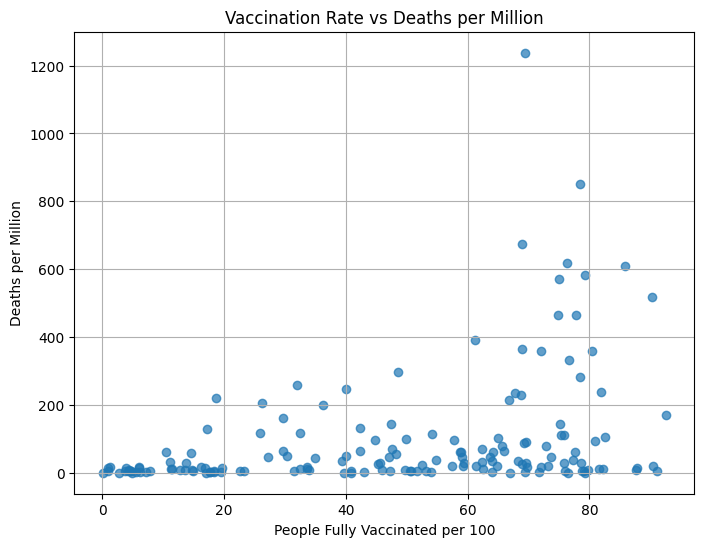

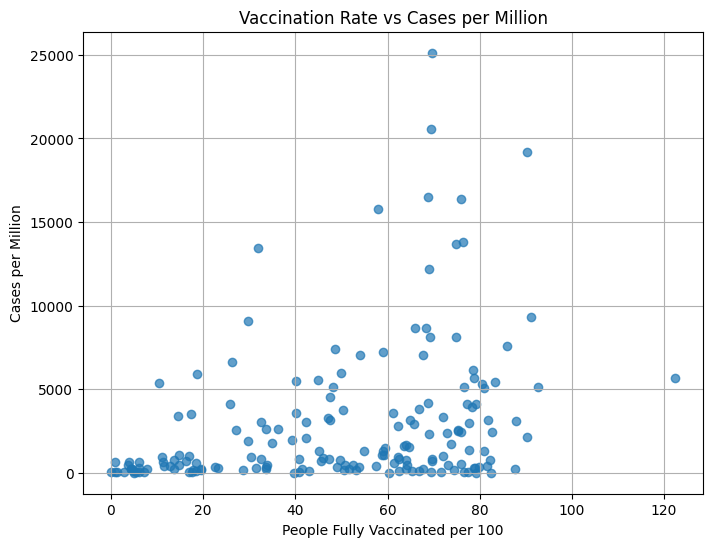

In [2]:
# import libraries to show data

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# load the csv files into set variables
vacc = pd.read_csv("country_vaccinations.csv")
world = pd.read_csv("worldometer_data.csv")

# too many dates in the vaccination folder so using the latest update gives the
# best and most available data
latest_vacc = vacc.sort_values('date').groupby('country').tail(1)

# grab specific columns that are connected to the hypothesis
vaccinations = latest_vacc[['country', 'people_fully_vaccinated_per_hundred']]
world_data = world[['Country/Region', 'Deaths/1M pop', 'Tot Cases/1M pop']]

# use pandas to connect countries so that the data from both can be used like
# sql joins
merged = pd.merge(vaccinations, world_data, left_on='country', right_on='Country/Region', how='inner')


# test the hypothesis to show if higher vaccination rate leads to lower deaths
# per million

# put specified columns into variables to plot
x = merged['people_fully_vaccinated_per_hundred']
y = merged['Deaths/1M pop']

# scatter plot with above x and y variables showing dots for vaccinations
# relating to total deaths
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.title("Vaccination Rate vs Deaths per Million")
plt.xlabel("People Fully Vaccinated per 100")
plt.ylabel("Deaths per Million")
plt.grid(True)
plt.show()


# similar to above, test if higher vaccination rate leads to fewer over all
# cases
# put specified columns into variables to plot
x2 = merged['people_fully_vaccinated_per_hundred']
y2 = merged['Tot Cases/1M pop']

# scatter plot with above x and y variables showing dots for vaccinations
# relating to total cases
plt.figure(figsize=(8, 6))
plt.scatter(x2, y2, alpha=0.7)
plt.title("Vaccination Rate vs Cases per Million")
plt.xlabel("People Fully Vaccinated per 100")
plt.ylabel("Cases per Million")

plt.grid(True)
plt.show()


                                     people_fully_vaccinated_per_hundred  \
people_fully_vaccinated_per_hundred                             1.000000   
Deaths/1M pop                                                   0.350636   
Tot Cases/1M pop                                                0.322476   

                                     Deaths/1M pop  Tot Cases/1M pop  
people_fully_vaccinated_per_hundred       0.350636          0.322476  
Deaths/1M pop                             1.000000          0.521924  
Tot Cases/1M pop                          0.521924          1.000000  


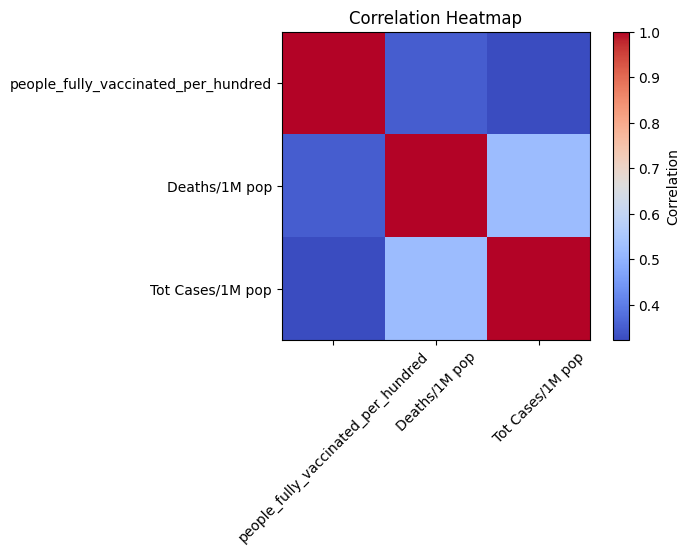

In [3]:


# correlation matrix to show if vaccinations did impact the deaths and cases
corr = merged[['people_fully_vaccinated_per_hundred', 'Deaths/1M pop', 'Tot Cases/1M pop']].corr()
print(corr)

# heatmap using default setup, comparing if the deaths and total cases correlate
# correctly with the vaccinations baased on our hypothesis
plt.figure(figsize=(6, 4))
plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

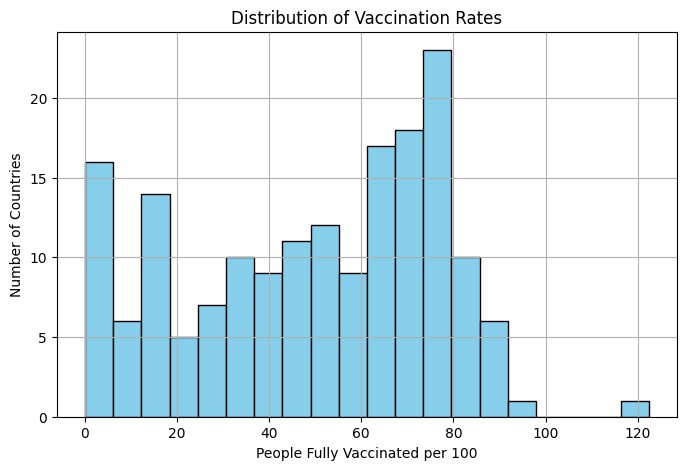

In [4]:
# basic histogram that shows how many countries have _ amount of vaccinations
# per 100 people
plt.figure(figsize=(8,5))
plt.hist(merged['people_fully_vaccinated_per_hundred'], bins=20, color='skyblue', edgecolor='black')
plt.title("Distribution of Vaccination Rates")
plt.xlabel("People Fully Vaccinated per 100")
plt.ylabel("Number of Countries")
plt.grid(True)
plt.show()

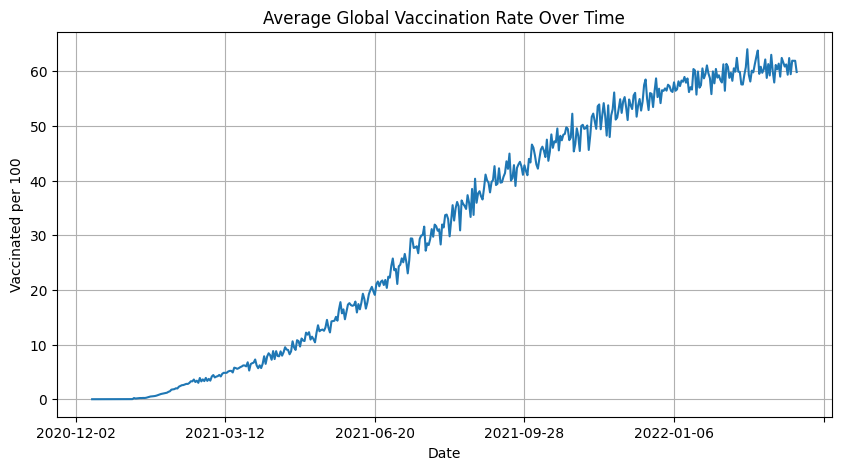

In [5]:
# this shows the average amount of population's vaccination over the time
# period, date shown is spaced between three months
vacc.groupby('date')['people_fully_vaccinated_per_hundred'].mean().plot(figsize=(10,5))
plt.title("Average Global Vaccination Rate Over Time")
plt.ylabel("Vaccinated per 100")
plt.xlabel("Date")
plt.grid(True)
plt.show()


https://pandas.pydata.org/docs/reference/api/pandas.merge.html documentation for how merge csvs works

https://www.mathworks.com/help/matlab/index.html documentation referenced for each diagram used

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html# docu used for correlation diagram/ heat map